In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Download dataset from Kaggle
import kagglehub

path = kagglehub.dataset_download("santoshd3/bank-customers")

# Find the CSV file
csv_files = [f for f in os.listdir(path) if f.endswith(".csv")]

print("CSV files found:", csv_files)

# Load the CSV
filename = os.path.join(path, csv_files[0])
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Using Colab cache for faster access to the 'bank-customers' dataset.
CSV files found: ['Churn Modeling.csv']
Dataset loaded successfully!
Rows: 10000
Columns: 14


In [64]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [65]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [66]:
df.isnull().sum()

,0
RowNumber,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


In [67]:
df.duplicated().sum()

np.int64(0)

In [68]:
df["Exited"].value_counts()

,count
Exited,
0,7963
1,2037


In [69]:
df["Exited"].value_counts(normalize=True) * 100

,proportion
Exited,
0,79.63
1,20.37


In [70]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [71]:
print("Geography:")
print(df["Geography"].value_counts())

print("\nGender:")
print(df["Gender"].value_counts())

Geography:
Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

Gender:
Gender
Male      5457
Female    4543
Name: count, dtype: int64


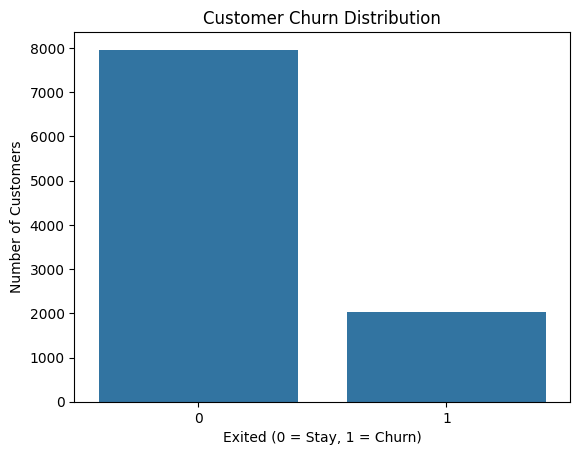

In [72]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x="Exited", data=df)

plt.title("Customer Churn Distribution")
plt.xlabel("Exited (0 = Stay, 1 = Churn)")
plt.ylabel("Number of Customers")
plt.show()

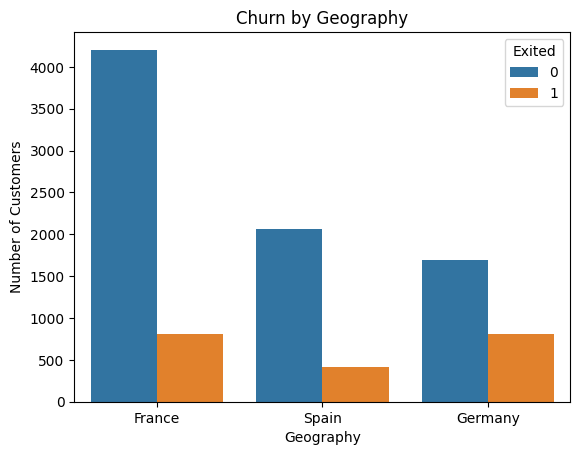

In [73]:
sns.countplot(x="Geography", hue="Exited", data=df)

plt.title("Churn by Geography")
plt.xlabel("Geography")
plt.ylabel("Number of Customers")
plt.show()

In [74]:
geo_churn = df.groupby("Geography")["Exited"].mean() * 100

print(geo_churn)

Geography
France     16.154767
Germany    32.443204
Spain      16.673395
Name: Exited, dtype: float64


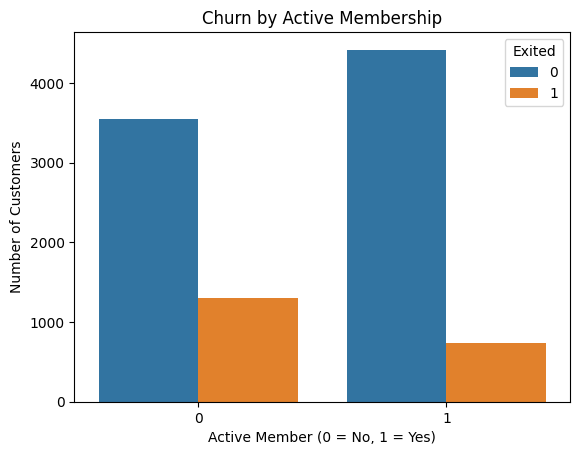

In [75]:
sns.countplot(x="IsActiveMember", hue="Exited", data=df)

plt.title("Churn by Active Membership")
plt.xlabel("Active Member (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()

In [76]:
active_churn = df.groupby("IsActiveMember")["Exited"].mean() * 100

print(active_churn)

IsActiveMember
0    26.850897
1    14.269074
Name: Exited, dtype: float64


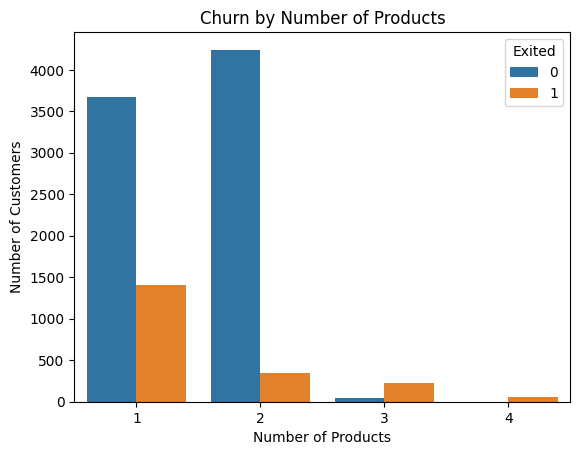

In [77]:
sns.countplot(x="NumOfProducts", hue="Exited", data=df)

plt.title("Churn by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Number of Customers")
plt.show()

In [78]:
product_churn = df.groupby("NumOfProducts")["Exited"].mean() * 100

print(product_churn)

NumOfProducts
1     27.714398
2      7.581699
3     82.706767
4    100.000000
Name: Exited, dtype: float64


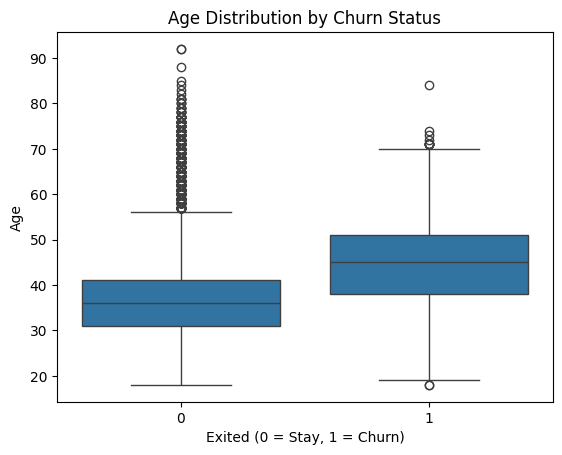

In [79]:
sns.boxplot(x="Exited", y="Age", data=df)

plt.title("Age Distribution by Churn Status")
plt.xlabel("Exited (0 = Stay, 1 = Churn)")
plt.ylabel("Age")
plt.show()

In [80]:
df.groupby("Exited")["Age"].mean()

,Age
Exited,
0,37.408389
1,44.837997


In [81]:
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[17, 30, 40, 50, 60, 100],
    labels=["18-30", "31-40", "41-50", "51-60", "61+"]
)

age_churn = df.groupby("AgeGroup", observed=True)["Exited"].mean() * 100

print(age_churn)

AgeGroup
18-30     7.520325
31-40    12.087171
41-50    33.965517
51-60    56.210790
61+      24.784483
Name: Exited, dtype: float64


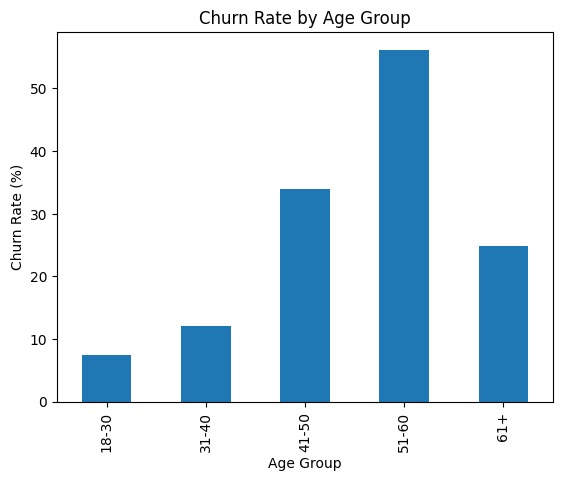

In [82]:
age_churn.plot(kind="bar")

plt.title("Churn Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Churn Rate (%)")
plt.show()

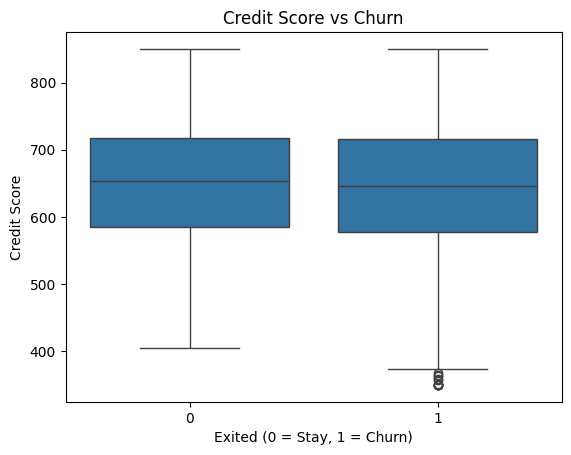

In [83]:
sns.boxplot(x="Exited", y="CreditScore", data=df)

plt.title("Credit Score vs Churn")
plt.xlabel("Exited (0 = Stay, 1 = Churn)")
plt.ylabel("Credit Score")
plt.show()

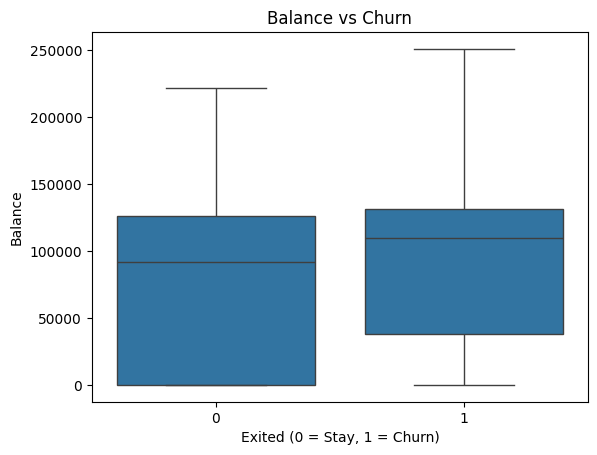

In [84]:
sns.boxplot(x="Exited", y="Balance", data=df)

plt.title("Balance vs Churn")
plt.xlabel("Exited (0 = Stay, 1 = Churn)")
plt.ylabel("Balance")
plt.show()

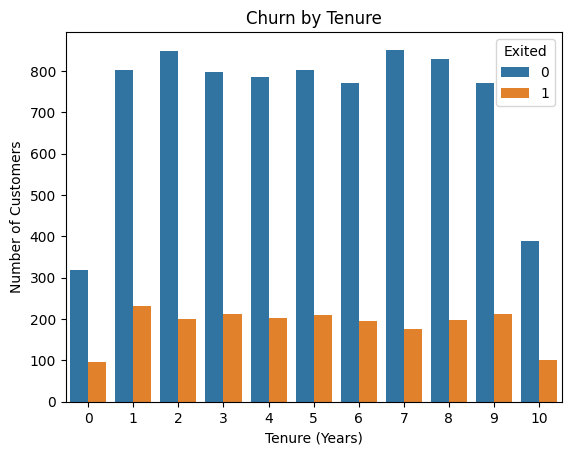

In [85]:
sns.countplot(x="Tenure", hue="Exited", data=df)

plt.title("Churn by Tenure")
plt.xlabel("Tenure (Years)")
plt.ylabel("Number of Customers")
plt.show()

In [86]:
tenure_churn = df.groupby("Tenure")["Exited"].mean() * 100

print(tenure_churn)

Tenure
0     23.002421
1     22.415459
2     19.179389
3     21.110010
4     20.525784
5     20.652174
6     20.268873
7     17.217899
8     19.219512
9     21.646341
10    20.612245
Name: Exited, dtype: float64


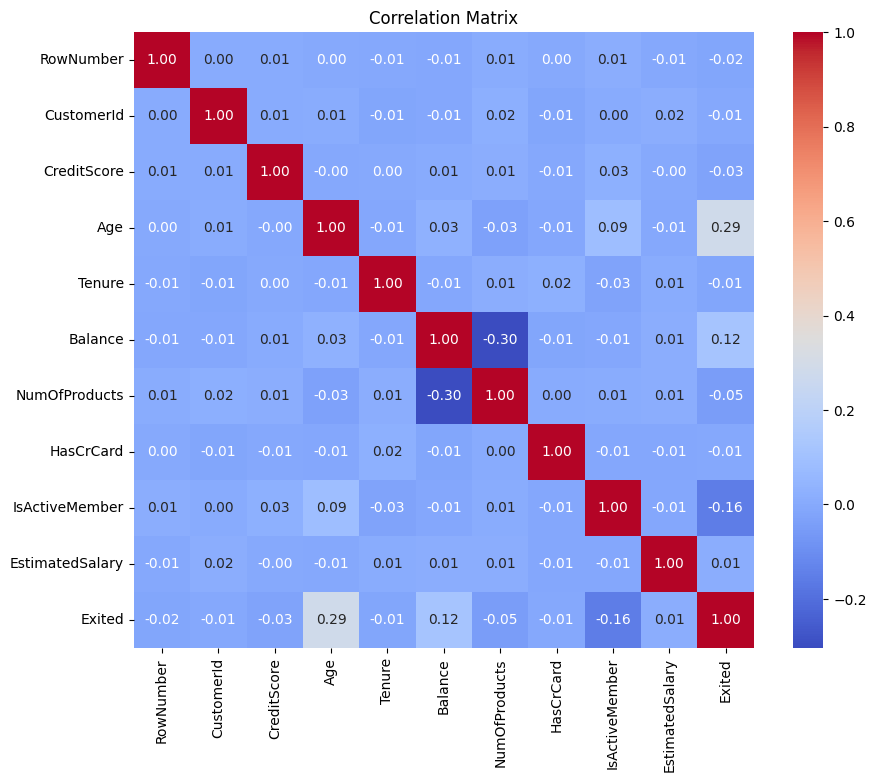

In [87]:
numeric_df = df.select_dtypes(include=["int64", "float64"])

correlation = numeric_df.corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

In [88]:
# Create numerical correlation matrix again
numeric_df = df.select_dtypes(include=["int64", "float64"])

correlation = numeric_df.corr()

# Get correlation with churn
churn_correlation = correlation["Exited"].sort_values(ascending=False)

print("Correlation with Churn (Exited):")
print(churn_correlation)

Correlation with Churn (Exited):
Exited             1.000000
Age                0.285323
Balance            0.118533
EstimatedSalary    0.012097
CustomerId        -0.006248
HasCrCard         -0.007138
Tenure            -0.014001
RowNumber         -0.016571
CreditScore       -0.027094
NumOfProducts     -0.047820
IsActiveMember    -0.156128
Name: Exited, dtype: float64


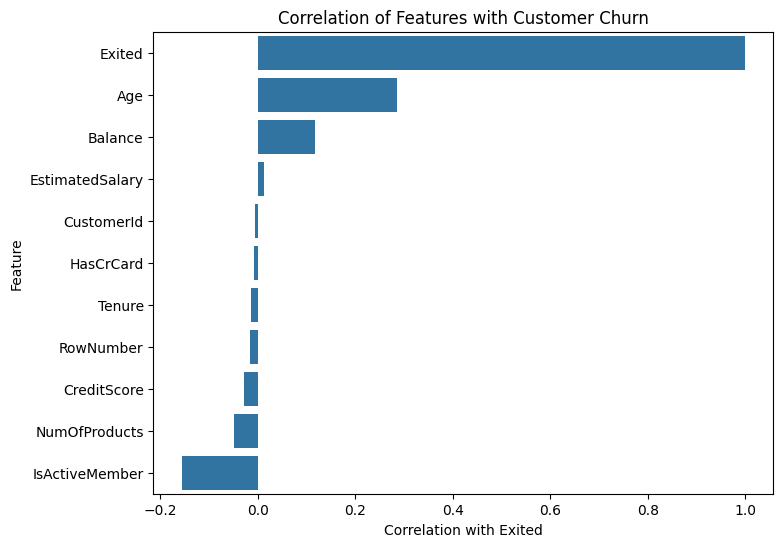

In [89]:
plt.figure(figsize=(8, 6))

sns.barplot(
    x=churn_correlation.values,
    y=churn_correlation.index
)

plt.title("Correlation of Features with Customer Churn")
plt.xlabel("Correlation with Exited")
plt.ylabel("Feature")

plt.show()

In [90]:

print("Strongest positive correlations with churn:")
print(churn_correlation.sort_values(ascending=False).head(5))

print("\nStrongest negative correlations with churn:")
print(churn_correlation.sort_values(ascending=True).head(5))

Strongest positive correlations with churn:
Exited             1.000000
Age                0.285323
Balance            0.118533
EstimatedSalary    0.012097
CustomerId        -0.006248
Name: Exited, dtype: float64

Strongest negative correlations with churn:
IsActiveMember   -0.156128
NumOfProducts    -0.047820
CreditScore      -0.027094
RowNumber        -0.016571
Tenure           -0.014001
Name: Exited, dtype: float64


In [91]:
X = df.drop("Exited", axis=1)
y = df["Exited"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (10000, 14)
Target shape: (10000,)


In [92]:
numeric_features = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary"
]

categorical_features = [
    "Geography",
    "Gender"
]

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']

Categorical features:
['Geography', 'Gender']


In [93]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (8000, 14)
Testing data: (2000, 14)


In [94]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training target distribution:
Exited
0    79.625
1    20.375
Name: proportion, dtype: float64

Testing target distribution:
Exited
0    79.65
1    20.35
Name: proportion, dtype: float64


In [95]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [96]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [97]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [98]:
preprocessor.transform(X_test)

array([[-0.68073539, -0.27993196,  0.68472287, ...,  0.        ,
         0.        ,  1.        ],
       [-1.30191518, -0.5649346 , -0.35097064, ...,  0.        ,
         0.        ,  1.        ],
       [-0.97061929,  0.10007155, -0.35097064, ...,  1.        ,
         1.        ,  0.        ],
       ...,
       [-1.39509214,  0.7650777 ,  1.3751852 , ...,  0.        ,
         1.        ,  0.        ],
       [ 0.39597623,  0.00507067,  0.68472287, ...,  0.        ,
         0.        ,  1.        ],
       [ 1.02750901, -0.5649346 , -1.04143297, ...,  0.        ,
         0.        ,  1.        ]])

In [99]:
print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

Original training shape: (8000, 14)
Processed training shape: (8000, 13)
Original testing shape: (2000, 14)
Processed testing shape: (2000, 13)


In [100]:
feature_names = preprocessor.get_feature_names_out()

print(feature_names)

['num__CreditScore' 'num__Age' 'num__Tenure' 'num__Balance'
 'num__NumOfProducts' 'num__HasCrCard' 'num__IsActiveMember'
 'num__EstimatedSalary' 'cat__Geography_France' 'cat__Geography_Germany'
 'cat__Geography_Spain' 'cat__Gender_Female' 'cat__Gender_Male']


In [101]:
X_train_processed_df = pd.DataFrame(
    X_train_processed.toarray() if hasattr(X_train_processed, "toarray") else X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_train_processed_df.head()

,num__CreditScore,num__Age,num__Tenure,num__Balance,num__NumOfProducts,num__HasCrCard,num__IsActiveMember,num__EstimatedSalary,cat__Geography_France,cat__Geography_Germany,cat__Geography_Spain,cat__Gender_Female,cat__Gender_Male
2151,1.058568,1.715086,0.684723,-1.226059,-0.910256,0.641042,-1.030206,1.042084,1.0,0.0,0.0,0.0,1.0
8392,0.913626,-0.659935,-0.696202,0.413288,-0.910256,0.641042,-1.030206,-0.623556,0.0,1.0,0.0,0.0,1.0
5006,1.079274,-0.184931,-1.731895,0.601687,0.808830,0.641042,0.970680,0.308128,0.0,1.0,0.0,1.0,0.0
4117,-0.929207,-0.184931,-0.005739,-1.226059,0.808830,0.641042,-1.030206,-0.290199,1.0,0.0,0.0,0.0,1.0
7182,0.427035,0.955079,0.339492,0.548318,0.808830,-1.559960,0.970680,0.135042,0.0,1.0,0.0,0.0,1.0


In [102]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [103]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(random_state=42))
    ]
)

In [104]:
logistic_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['CreditScore', 'Age',
                                                   'Tenure', 'Balance',
                                                   'NumOfProducts', 'HasCrCard',
                                                   'IsActiveMember',
                                                   'EstimatedSalary']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Geography', 'Gender'])])),
                ('classifier', LogisticRegression(random_state=42))])

In [105]:
from sklearn.tree import DecisionTreeClassifier

In [106]:
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            random_state=42,
            max_depth=5
        ))
    ]
)

In [107]:
decision_tree_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['CreditScore', 'Age',
                                                   'Tenure', 'Balance',
                                                   'NumOfProducts', 'HasCrCard',
                                                   'IsActiveMember',
                                                   'EstimatedSalary']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Geography', 'Gender'])])),
                ('classifier',
                 DecisionTreeClassifier(max_depth=5, random_state=42))])

In [108]:
from sklearn.ensemble import RandomForestClassifier

In [109]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ]
)

In [110]:
random_forest_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['CreditScore', 'Age',
                                                   'Tenure', 'Balance',
                                                   'NumOfProducts', 'HasCrCard',
                                                   'IsActiveMember',
                                                   'EstimatedSalary']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Geography', 'Gender'])])),
                ('classifier', RandomForestClassifier(random_state=42))])

In [111]:
y_pred_logistic = logistic_model.predict(X_test)

In [112]:
y_pred_tree = decision_tree_model.predict(X_test)

In [113]:
y_pred_forest = random_forest_model.predict(X_test)

In [114]:
print("Logistic Regression predictions:")
print(y_pred_logistic[:20])

print("\nDecision Tree predictions:")
print(y_pred_tree[:20])

print("\nRandom Forest predictions:")
print(y_pred_forest[:20])

Logistic Regression predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0]

Decision Tree predictions:
[0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0]

Random Forest predictions:
[0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 1 1]


In [115]:
from sklearn.metrics import accuracy_score

print("Logistic Regression:",
      accuracy_score(y_test, y_pred_logistic))

print("Decision Tree:",
      accuracy_score(y_test, y_pred_tree))

print("Random Forest:",
      accuracy_score(y_test, y_pred_forest))

Logistic Regression: 0.808
Decision Tree: 0.856
Random Forest: 0.8575


In [116]:
from sklearn.metrics import classification_report

print("Logistic Regression")
print(classification_report(y_test, y_pred_logistic))

print("Decision Tree")
print(classification_report(y_test, y_pred_tree))

print("Random Forest")
print(classification_report(y_test, y_pred_forest))

Logistic Regression
              precision    recall  f1-score   support

           0       0.82      0.97      0.89      1593
           1       0.59      0.19      0.28       407

    accuracy                           0.81      2000
   macro avg       0.71      0.58      0.59      2000
weighted avg       0.78      0.81      0.77      2000

Decision Tree
              precision    recall  f1-score   support

           0       0.86      0.97      0.91      1593
           1       0.79      0.40      0.53       407

    accuracy                           0.86      2000
   macro avg       0.83      0.69      0.72      2000
weighted avg       0.85      0.86      0.84      2000

Random Forest
              precision    recall  f1-score   support

           0       0.87      0.97      0.92      1593
           1       0.76      0.43      0.55       407

    accuracy                           0.86      2000
   macro avg       0.82      0.70      0.73      2000
weighted avg       0.85   

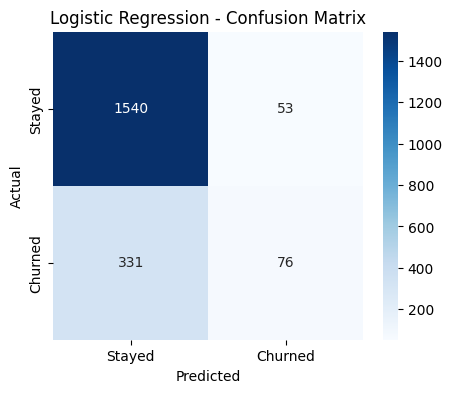

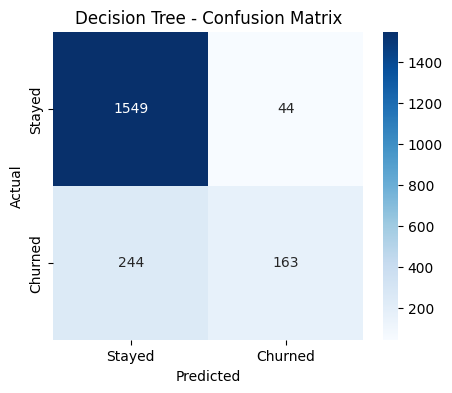

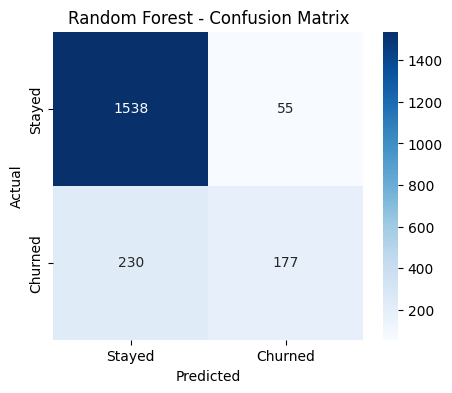

In [117]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

models = {
    "Logistic Regression": y_pred_logistic,
    "Decision Tree": y_pred_tree,
    "Random Forest": y_pred_forest
}

for name, predictions in models.items():
    cm = confusion_matrix(y_test, predictions)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Stayed", "Churned"],
        yticklabels=["Stayed", "Churned"]
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"{name} - Confusion Matrix")
    plt.show()

In [118]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_logistic),
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test, y_pred_forest)
    ],
    "Churn Precision": [
        0.59,
        0.79,
        0.76
    ],
    "Churn Recall": [
        0.19,
        0.40,
        0.43
    ],
    "Churn F1-Score": [
        0.28,
        0.53,
        0.55
    ]
})

print(model_comparison)

                 Model  Accuracy  Churn Precision  Churn Recall  \
0  Logistic Regression    0.8080             0.59          0.19   
1        Decision Tree    0.8560             0.79          0.40   
2        Random Forest    0.8575             0.76          0.43   

   Churn F1-Score  
0            0.28  
1            0.53  
2            0.55  


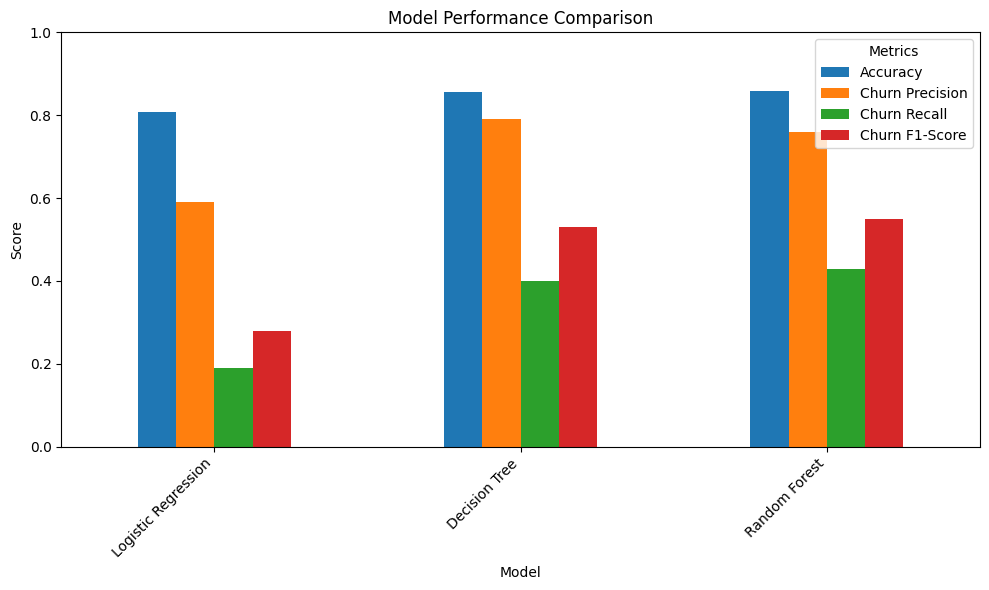

In [154]:
comparison_plot = model_comparison.set_index("Model")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

In [120]:

preprocessor_fitted = random_forest_model.named_steps["preprocessor"]


feature_names = preprocessor_fitted.get_feature_names_out()

print("Number of processed features:", len(feature_names))
print(feature_names)

Number of processed features: 13
['num__CreditScore' 'num__Age' 'num__Tenure' 'num__Balance'
 'num__NumOfProducts' 'num__HasCrCard' 'num__IsActiveMember'
 'num__EstimatedSalary' 'cat__Geography_France' 'cat__Geography_Germany'
 'cat__Geography_Spain' 'cat__Gender_Female' 'cat__Gender_Male']


In [121]:

importances = random_forest_model.named_steps["classifier"].feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})


feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance_df)

                   Feature  Importance
1                 num__Age    0.239305
7     num__EstimatedSalary    0.147076
0         num__CreditScore    0.144092
3             num__Balance    0.140818
4       num__NumOfProducts    0.127426
2              num__Tenure    0.083448
6      num__IsActiveMember    0.037625
9   cat__Geography_Germany    0.022950
5           num__HasCrCard    0.019086
8    cat__Geography_France    0.010522
10    cat__Geography_Spain    0.009955
12        cat__Gender_Male    0.009077
11      cat__Gender_Female    0.008619


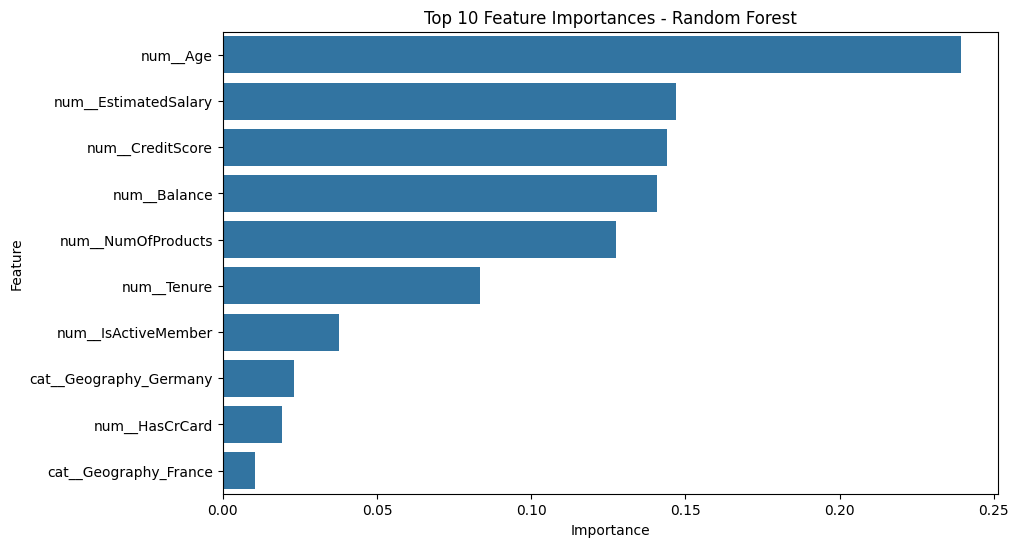

In [122]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

In [123]:
print("Training set class distribution:")
print(y_train.value_counts())

print("\nTraining set class percentages:")
print(y_train.value_counts(normalize=True) * 100)

Training set class distribution:
Exited
0    6370
1    1630
Name: count, dtype: int64

Training set class percentages:
Exited
0    79.625
1    20.375
Name: proportion, dtype: float64


In [124]:
from sklearn.linear_model import LogisticRegression

logistic_balanced = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

logistic_balanced.fit(X_train, y_train)

y_pred_logistic_balanced = logistic_balanced.predict(X_test)

print(classification_report(y_test, y_pred_logistic_balanced))

              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1593
           1       0.39      0.70      0.50       407

    accuracy                           0.71      2000
   macro avg       0.65      0.71      0.65      2000
weighted avg       0.80      0.71      0.74      2000



In [125]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_balanced = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

decision_tree_balanced.fit(X_train, y_train)

y_pred_tree_balanced = decision_tree_balanced.predict(X_test)

print(classification_report(y_test, y_pred_tree_balanced))

              precision    recall  f1-score   support

           0       0.87      0.86      0.86      1593
           1       0.47      0.47      0.47       407

    accuracy                           0.78      2000
   macro avg       0.67      0.67      0.67      2000
weighted avg       0.78      0.78      0.78      2000



In [126]:
from sklearn.ensemble import RandomForestClassifier

random_forest_balanced = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        class_weight="balanced",
        n_estimators=100,
        random_state=42
    ))
])

random_forest_balanced.fit(X_train, y_train)

y_pred_forest_balanced = random_forest_balanced.predict(X_test)

print(classification_report(y_test, y_pred_forest_balanced))

              precision    recall  f1-score   support

           0       0.87      0.97      0.92      1593
           1       0.77      0.43      0.55       407

    accuracy                           0.86      2000
   macro avg       0.82      0.70      0.73      2000
weighted avg       0.85      0.86      0.84      2000



In [127]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    random_forest_balanced,
    X_train,
    y_train,
    cv=5,
    scoring="f1"
)

print("Cross-validation F1 scores:")
print(cv_scores)

print("\nMean F1-score:", cv_scores.mean())
print("Standard deviation:", cv_scores.std())

Cross-validation F1 scores:
[0.52918288 0.56573705 0.50909091 0.56       0.58167331]

Mean F1-score: 0.5491368294068156
Standard deviation: 0.026283204042578476


In [128]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2]
}

grid_search = GridSearchCV(
    estimator=random_forest_balanced,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(grid_search.best_score_)

Best Parameters:
{'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}

Best Cross-Validation F1-Score:
0.6262191892776354


In [129]:

best_rf = grid_search.best_estimator_


y_pred_tuned_rf = best_rf.predict(X_test)

print("Tuned Random Forest Classification Report:")
print(classification_report(y_test, y_pred_tuned_rf))

Tuned Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.88      0.90      1593
           1       0.59      0.65      0.62       407

    accuracy                           0.84      2000
   macro avg       0.75      0.77      0.76      2000
weighted avg       0.84      0.84      0.84      2000



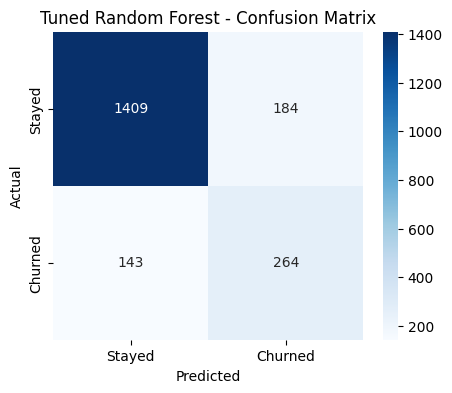

In [130]:
cm_tuned_rf = confusion_matrix(y_test, y_pred_tuned_rf)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_tuned_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Tuned Random Forest - Confusion Matrix")

plt.show()

In [131]:
from sklearn.metrics import roc_auc_score


y_prob_tuned_rf = best_rf.predict_proba(X_test)[:, 1]


roc_auc = roc_auc_score(y_test, y_prob_tuned_rf)

print("Tuned Random Forest ROC-AUC:", roc_auc)

Tuned Random Forest ROC-AUC: 0.8586629773070452


In [132]:
import pandas as pd

final_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Balanced Logistic Regression",
        "Balanced Decision Tree",
        "Balanced Random Forest",
        "Tuned Random Forest"
    ],
    "Accuracy": [
        0.81,
        0.86,
        0.86,
        0.71,
        0.78,
        0.86,
        0.84
    ],
    "Churn Precision": [
        0.59,
        0.79,
        0.76,
        0.39,
        0.47,
        0.77,
        0.59
    ],
    "Churn Recall": [
        0.19,
        0.40,
        0.43,
        0.70,
        0.47,
        0.43,
        0.65
    ],
    "Churn F1": [
        0.28,
        0.53,
        0.55,
        0.50,
        0.47,
        0.55,
        0.62
    ]
})

print(final_comparison.to_string(index=False))

                       Model  Accuracy  Churn Precision  Churn Recall  Churn F1
         Logistic Regression      0.81             0.59          0.19      0.28
               Decision Tree      0.86             0.79          0.40      0.53
               Random Forest      0.86             0.76          0.43      0.55
Balanced Logistic Regression      0.71             0.39          0.70      0.50
      Balanced Decision Tree      0.78             0.47          0.47      0.47
      Balanced Random Forest      0.86             0.77          0.43      0.55
         Tuned Random Forest      0.84             0.59          0.65      0.62


In [153]:
import joblib

joblib.dump(best_rf, "churn_model.pkl")

print("Final churn model saved successfully!")


Final churn model saved successfully!


In [152]:
import pandas as pd

credit_score = int(input("Credit Score: "))
geography = input("Geography (France/Germany/Spain): ")
gender = input("Gender (Male/Female): ")
age = int(input("Age: "))
tenure = int(input("Tenure (years): "))
balance = float(input("Balance: "))
num_products = int(input("Number of Products: "))
has_card = int(input("Has Credit Card? (1=Yes, 0=No): "))
active_member = int(input("Is Active Member? (1=Yes, 0=No): "))
salary = float(input("Estimated Salary: "))

customer = pd.DataFrame({
    "CreditScore": [credit_score],
    "Geography": [geography],
    "Gender": [gender],
    "Age": [age],
    "Tenure": [tenure],
    "Balance": [balance],
    "NumOfProducts": [num_products],
    "HasCrCard": [has_card],
    "IsActiveMember": [active_member],
    "EstimatedSalary": [salary]
})

prediction = best_rf.predict(customer)[0]

churn_probability = best_rf.predict_proba(customer)[0][1]
stay_probability = best_rf.predict_proba(customer)[0][0]

if prediction == 1:
    result = "CHURN"
else:
    result = "STAY"

print("\nPrediction:", result)
print(f"Churn Probability: {churn_probability * 100:.2f}%")
print(f"Stay Probability: {stay_probability * 100:.2f}%")

Credit Score: 650
Geography (France/Germany/Spain): france
Gender (Male/Female): male
Age: 32
Tenure (years): 5
Balance: 455555
Number of Products: 55
Has Credit Card? (1=Yes, 0=No): 0
Is Active Member? (1=Yes, 0=No): 1
Estimated Salary: 85000

Prediction: CHURN
Churn Probability: 72.57%
Stay Probability: 27.43%
